# Exact single-frequency Mott–Schottky exploration

This standalone workflow reads the full CSV in chunks. Strict matching means numerically identical measured frequencies; no interpolation or automatic nearest-frequency substitute is used. A selected frequency and a corrected-bias regression interval each require separate explicit confirmation. A nearest-frequency analysis is deliberately not implemented.

The apparent capacitance is not automatically depletion capacitance; neither the intercept nor slope establishes flat-band potential or semiconductor type. All capacitances are total capacitance. The measured Au-vs-FTO bias and a separate user-specified corrected convention (measured − 0.2 V) are retained; the latter is not a verified internal potential.

In [29]:
from pathlib import Path
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from single_frequency import load_spectra, audit_frequencies, extract_cut, regress_cut, PhaseGate
from speis_fitting import carrier_density

FILE_PATH = Path('BiSI - IV_EIS_IV_1to-1_Electrode12_30m_more_time_02_SPEIS_C03.csv')
CHUNK_SIZE = 100_000
VOLTAGE_OFFSET_V = -0.2  # convention, not a verified potential
AREA_CM2, RELATIVE_PERMITTIVITY, ASSUMED_TEMPERATURE_K = 0.09, 38.0, 298.15
# None means explicitly include all detected contiguous sweeps; otherwise list IDs.
SELECTED_SPECTRUM_IDS = None
GATE = PhaseGate(low_hz=50_000, high_hz=100_000, target_deg=-85,
                 max_deviation_deg=5, max_range_deg=10, max_neighbor_change_deg=10)
print('Assumptions:', {'area_cm2': AREA_CM2, 'relative_permittivity': RELATIVE_PERMITTIVITY,
                        'assumed_temperature_K_not_monitored': ASSUMED_TEMPERATURE_K,
                        'voltage_offset_V': VOLTAGE_OFFSET_V, 'phase_gate': asdict(GATE)})

Assumptions: {'area_cm2': 0.09, 'relative_permittivity': 38.0, 'assumed_temperature_K_not_monitored': 298.15, 'voltage_offset_V': -0.2, 'phase_gate': {'low_hz': 50000, 'high_hz': 100000, 'target_deg': -85, 'max_deviation_deg': 5, 'max_range_deg': 10, 'max_neighbor_change_deg': 10}}


## Load and audit

The loader treats zero-frequency/zero-impedance rows as non-EIS sentinels. Other nonpositive or nonfinite frequencies are retained separately as ungroupable evidence; all positive-frequency rows, including invalid impedance or voltage, enter contiguous sweep grouping. Source row numbers are zero-based CSV data-row positions. Grouping and completeness flags need review.

eEach band candidate is evaluated over the **same selected sweeps**. Passing requires a unique valid row in every sweep, phase within the configured maximum deviation of the target, a phase range within the configured maximum, and at least one immediately adjacent distinct measured frequency in each sweep with a unique valid row and phase change within the configured maximum. The values come from `GATE` above. These configurable thresholds are heuristics, not universal plateau or physical-validity tests. Instrument phase agreement uses wrapped angular difference.

Loading: {'total_rows': 375172, 'zero_frequency_zero_impedance_sentinels': 373786, 'positive_frequency_rows': 1386, 'positive_rows_invalid_impedance_or_voltage': 0, 'ungroupable_frequency_rows': 0} ; detected sweeps: 21 ; selected: 21


,id,cycle,measured_V,corrected_V,spread_V,points,flags
0,1,1.0,-1.000324,-1.200324,0.000111,66,
1,2,2.0,-0.900366,-1.100366,0.000135,66,
2,3,3.0,-0.800278,-1.000278,0.000104,66,
3,4,4.0,-0.700334,-0.900334,0.000123,66,
4,5,5.0,-0.600343,-0.800343,0.000109,66,
5,6,6.0,-0.500300,-0.700300,0.000126,66,
6,7,7.0,-0.400324,-0.600324,0.000129,66,
7,8,8.0,-0.300369,-0.500369,0.000115,66,
8,9,9.0,-0.200380,-0.400380,0.000118,66,
9,10,10.0,-0.100321,-0.300321,0.000144,66,


Exact common frequencies across selected sweeps: 66; in band: 3; passing: 0
Common frequencies in Hz: [0.99853009, 1.9970602, 2.9955902, 3.9941204, 4.99265, 5.9911804, 7.9882407, 10.152682, 12.807399, 16.141535, 20.358339, 25.665239, 32.349899, 40.796326, 51.431881, 64.854698, 81.752983, 103.11902, 129.95824, 163.89862, 206.65303, 260.58405, 328.63318, 414.33722, 522.17242, 658.52478, 830.26288, 1046.6725, 1319.5798, 1664.4672, 2097.9866, 2645.8501, 3336.0645, 4206.3447, 5302.9956, 6686.1958, 8427.9775, 10633.163, 13398.155, 16896.158, 21303.445, 26861.266, 33875.816, 42708.949, 53852.43, 67890.805, 85603.477, 107936.83, 136087.81, 171587.36, 216346.88, 272778.72, 343935.56, 433649.41, 546763.69, 689392.81, 869219.5, 1095958.3, 1381829.0, 1742298.9, 2196760.0, 2769781.8, 3492271.0, 4403234.5, 5551811.0, 7000018.5] (first 100)
No exact common frequency passes all phase and neighboring heuristics; strict analysis stopped. No replacement selected.
Band candidates ranked: passing first, th

,frequency_hz,exact_common,missing_sweeps,duplicate_sweeps,invalid_sweeps,median_deviation_deg,max_deviation_deg,phase_range_deg,neighbor_fail_sweeps,passes
0,85603.477,True,0,0,0,1.156027,67.931337,69.087364,0,False
1,67890.805,True,0,0,0,1.306284,70.889042,72.195326,0,False
2,53852.430,True,0,0,0,1.346446,73.601893,74.948339,0,False


Per-sweep evidence retained in phase_detail; preview of first candidate:


,frequency_hz,spectrum_id,cycle,bias_measured_v,bias_corrected_v,spectrum_flags,count,source_row,point_bias_v,phase_deg,instrument_phase_deg,instrument_phase_difference_deg,lower_hz,lower_change_deg,upper_hz,upper_change_deg,neighbor_pass
42,85603.477,1,1.0,-1.000324,-1.200324,,1,17900.0,-1.000338,-82.333866,-82.333870,3.802100e-06,67890.805,0.755343,107936.83,0.507859,True
43,85603.477,2,2.0,-0.900366,-1.100366,,1,35856.0,-0.900371,-83.765734,-83.765732,2.325229e-06,67890.805,0.434504,107936.83,0.129397,True
44,85603.477,3,3.0,-0.800278,-1.000278,,1,53875.0,-0.800302,-84.581278,-84.581276,2.231427e-06,67890.805,0.108483,107936.83,0.095650,True
45,85603.477,4,4.0,-0.700334,-0.900334,,1,71896.0,-0.700334,-85.234846,-85.234848,2.317934e-06,67890.805,0.101353,107936.83,0.216305,True
46,85603.477,5,5.0,-0.600343,-0.800343,,1,89870.0,-0.600347,-85.390670,-85.390671,1.058893e-06,67890.805,0.243940,107936.83,0.089018,True
47,85603.477,6,6.0,-0.500300,-0.700300,,1,107826.0,-0.500312,-85.735874,-85.735878,3.696592e-06,67890.805,0.088888,107936.83,0.210944,True
48,85603.477,7,7.0,-0.400324,-0.600324,,1,125782.0,-0.400335,-86.156027,-86.156029,2.200032e-06,67890.805,0.066171,107936.83,0.467629,True
49,85603.477,8,8.0,-0.300369,-0.500369,,1,143738.0,-0.300383,-86.018671,-86.018669,2.407982e-06,67890.805,0.231824,107936.83,0.200329,True
50,85603.477,9,9.0,-0.200380,-0.400380,,1,161657.0,-0.200402,-86.003160,-86.003159,1.141673e-06,67890.805,0.303124,107936.83,0.352363,True
51,85603.477,10,10.0,-0.100321,-0.300321,,1,179446.0,-0.100321,-85.907613,-85.907616,3.217753e-06,67890.805,0.300761,107936.83,0.240621,True


Instrument phase comparison: {'count': 63, 'max_abs_difference_deg': 4.092194956228923e-06}


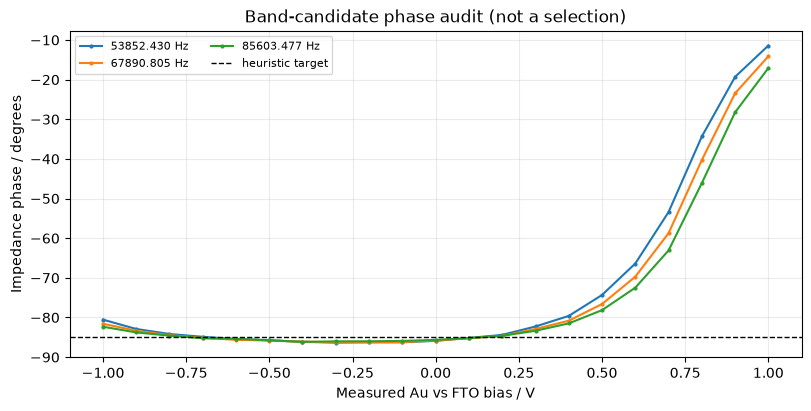

In [30]:
spectra, ungroupable, load_audit = load_spectra(FILE_PATH, chunksize=CHUNK_SIZE, direction='descending',
                                                  expected_frequency_range=(1.0, 7e6), frequency_tolerance=0.05)
if SELECTED_SPECTRUM_IDS is None:
    selected = spectra
else:
    requested = set(SELECTED_SPECTRUM_IDS)
    selected = [s for s in spectra if s.spectrum_id in requested]
    if len(requested) != len(SELECTED_SPECTRUM_IDS) or requested != {s.spectrum_id for s in selected}:
        raise ValueError('Spectrum IDs must be unique and exist in the grouping')
print('Loading:', load_audit, '; detected sweeps:', len(spectra), '; selected:', len(selected))
if not ungroupable.empty:
    print('Ungroupable rows retained in `ungroupable`; first 10:')
    display(ungroupable.head(10))
sweep_table = pd.DataFrame([{'id': s.spectrum_id, 'cycle': s.cycle, 'measured_V': s.voltage_v,
                             'corrected_V': s.voltage_v + VOLTAGE_OFFSET_V, 'spread_V': s.voltage_spread_v,
                             'points': len(s.data), 'flags': ', '.join(s.flags)} for s in selected])
display(sweep_table.head(30))
candidates, phase_detail, common_frequencies = audit_frequencies(selected, GATE, voltage_offset_v=VOLTAGE_OFFSET_V)
print(f'Exact common frequencies across selected sweeps: {len(common_frequencies)}; in band: {int(candidates.exact_common.sum())}; passing: {int(candidates.passes.sum())}')
print('Common frequencies in Hz:', [float(f) for f in common_frequencies[:100]], '(first 100)')
if not selected:
    print('No selected sweeps; strict analysis stopped.')
elif not common_frequencies:
    print('No exact common measured frequency across the selected sweeps; strict analysis stopped.')
elif not candidates.exact_common.any():
    print('No exact common measured frequency in the configured band; strict analysis stopped.')
elif not candidates.passes.any():
    print('No exact common frequency passes all phase and neighboring heuristics; strict analysis stopped. No replacement selected.')
print('Band candidates ranked: passing first, then median deviation, phase range and frequency.')
display(candidates.head(30))
if not phase_detail.empty:
    print('Per-sweep evidence retained in phase_detail; preview of first candidate:')
    display(phase_detail[phase_detail.frequency_hz == candidates.iloc[0].frequency_hz].head(30))
    diff = phase_detail.instrument_phase_difference_deg.dropna()
    print('Instrument phase comparison:', {'count': len(diff), 'max_abs_difference_deg': float(diff.max()) if len(diff) else None})
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    for f, part in phase_detail.groupby('frequency_hz', sort=True):
        ax.plot(part.bias_measured_v, part.phase_deg, '.-', ms=4, label=f'{f:.3f} Hz')
    ax.axhline(GATE.target_deg, color='black', ls='--', lw=1, label='heuristic target')
    ax.set(xlabel='Measured Au vs FTO bias / V', ylabel='Impedance phase / degrees',
           title='Band-candidate phase audit (not a selection)')
    ax.grid(alpha=.25)
    ax.legend(fontsize=8, ncol=2)
    plt.show()
    plt.close(fig)

## Compare all three frequencies: measured bias −1 to +0.25 V

This exploratory comparison uses the inclusive **measured Au-versus-FTO bias** range entered below, applied to each spectrum's median voltage. It checks which actual measured frequencies are exactly common to all spectra in that range and lie in the configured band. No interpolation, frequency selection, or series-resistance correction is used. Because endpoints use actual measured values, a spectrum nominally at −1 V may fall just outside the limit; the table below reports its inclusion explicitly.

For each frequency $C_p=\operatorname{Im}(1/Z)/(2\pi f)$ is the total parallel apparent capacitance, and $1/C_p^2$ is calculated from it. Circles meet the configured per-point phase-target and neighboring-frequency checks; crosses fail either check. These symbols do **not** show whether the candidate passes the across-bias phase-range test or whether the sweep passes other QC. All valid points are shown, even if a check fails. The linear lines use all valid points in the specified range and are descriptive only; they do not establish a valid Mott–Schottky region, depletion capacitance, or carrier concentration.

Inclusive measured range [-1, 0.25] V: 12 of 21 spectra.
Spectrum inclusion audit (actual median voltages):


,spectrum_id,measured_V,corrected_V,in_range,flags
0,1,-1.000324,-1.200324,False,
1,2,-0.900366,-1.100366,True,
2,3,-0.800278,-1.000278,True,
3,4,-0.700334,-0.900334,True,
4,5,-0.600343,-0.800343,True,
5,6,-0.500300,-0.700300,True,
6,7,-0.400324,-0.600324,True,
7,8,-0.300369,-0.500369,True,
8,9,-0.200380,-0.400380,True,
9,10,-0.100321,-0.300321,True,


Exact common band frequencies (Hz): [53852.43, 67890.805, 85603.477]
Global phase checks across the selected range:


,frequency_hz,exact_common,missing_sweeps,duplicate_sweeps,invalid_sweeps,median_deviation_deg,max_deviation_deg,phase_range_deg,neighbor_fail_sweeps,passes
0,85603.477,True,0,0,0,0.695870,1.234266,2.390292,0,True
1,67890.805,True,0,0,0,0.817820,1.668769,2.975053,0,True
2,53852.430,True,0,0,0,0.866546,2.106762,3.453207,0,True


Point validity counts; values and detailed flags are retained in frequency_comparison:


,frequency_Hz,status,points
0,53852.430,valid,12
1,67890.805,valid,12
2,85603.477,valid,12


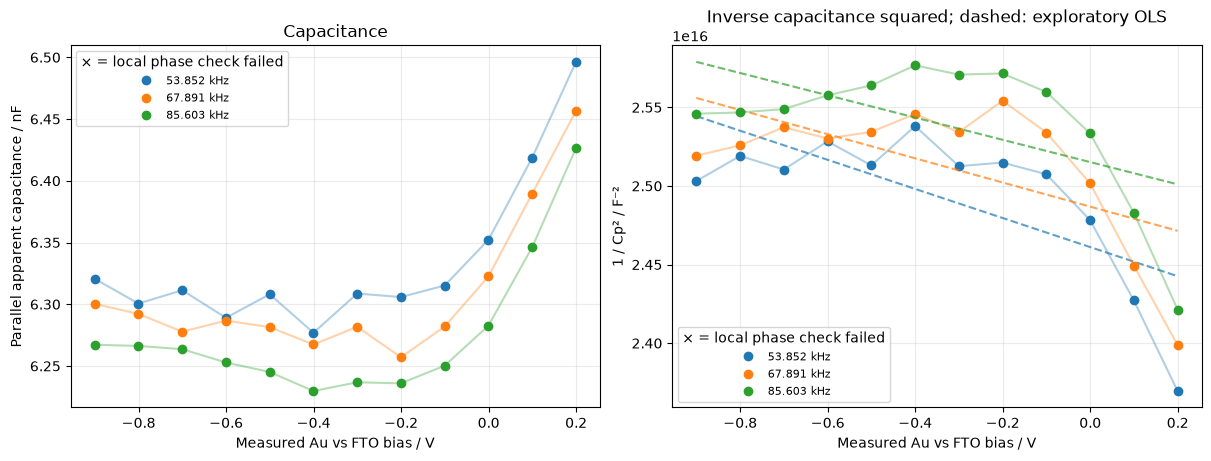

Descriptive unweighted fits over all valid points; not a depletion-model or density determination:


,frequency_Hz,n_valid,local_phase_failures,slope_F_minus2_per_V,slope_std_F_minus2_per_V,R_squared,x_intercept_measured_V,fit_flags
0,53852.430,12,0,-9.254078e+14,3.060038e+14,0.477687,26.594635,intercept_extrapolated
1,67890.805,12,0,-7.681845e+14,3.128768e+14,0.376098,32.372833,intercept_extrapolated
2,85603.477,12,0,-7.082992e+14,3.230960e+14,0.324591,35.510049,intercept_extrapolated


In [31]:
# Exact inclusive range uses measured median bias, not corrected bias.
COMPARE_MEASURED_MIN_V, COMPARE_MEASURED_MAX_V = -1.0, 0.25
from speis_fitting import linear_regression, inverse_capacitance_squared
if not np.isfinite([COMPARE_MEASURED_MIN_V, COMPARE_MEASURED_MAX_V]).all() or COMPARE_MEASURED_MIN_V >= COMPARE_MEASURED_MAX_V:
    raise ValueError('Enter finite, increasing measured-bias bounds.')
compare_spectra = [s for s in spectra if np.isfinite(s.voltage_v) and COMPARE_MEASURED_MIN_V <= s.voltage_v <= COMPARE_MEASURED_MAX_V]
compare_ids = {s.spectrum_id for s in compare_spectra}
range_audit = pd.DataFrame([{'spectrum_id': s.spectrum_id, 'measured_V': s.voltage_v,
                             'corrected_V': s.voltage_v + VOLTAGE_OFFSET_V,
                             'in_range': s.spectrum_id in compare_ids, 'flags': ', '.join(s.flags)} for s in spectra])
print(f'Inclusive measured range [{COMPARE_MEASURED_MIN_V:g}, {COMPARE_MEASURED_MAX_V:g}] V: {len(compare_spectra)} of {len(spectra)} spectra.')
print('Spectrum inclusion audit (actual median voltages):')
display(range_audit.head(30))
compare_candidates, compare_phase_detail, compare_common = audit_frequencies(compare_spectra, GATE, voltage_offset_v=VOLTAGE_OFFSET_V)
compare_frequencies = compare_candidates.loc[compare_candidates.exact_common, 'frequency_hz'].sort_values().tolist()
print('Exact common band frequencies (Hz):', compare_frequencies)
print('Global phase checks across the selected range:')
display(compare_candidates.head(30))
comparison_points = []
for frequency in compare_frequencies:
    details = compare_phase_detail.loc[compare_phase_detail.frequency_hz == frequency].set_index('spectrum_id')
    for spectrum in compare_spectra:
        match = spectrum.data.loc[pd.to_numeric(spectrum.data['freq/Hz'], errors='coerce') == frequency]
        record = {'frequency_Hz': frequency, 'spectrum_id': spectrum.spectrum_id,
                  'measured_V': spectrum.voltage_v, 'corrected_V': spectrum.voltage_v + VOLTAGE_OFFSET_V,
                  'source_row': None, 'phase_deg': np.nan, 'Cp_F': np.nan, 'inv_Cp2_F_minus2': np.nan,
                  'local_phase_pass': False, 'spectrum_flags': ', '.join(spectrum.flags),
                  'status': 'missing_or_duplicate_frequency'}
        if len(match) == 1:
            row = match.iloc[0]
            re = pd.to_numeric(row['Re(Z)/Ohm'], errors='coerce')
            neg_im = pd.to_numeric(row['-Im(Z)/Ohm'], errors='coerce')
            record['source_row'] = row['_row']
            record['status'] = 'invalid_or_noncapacitive'
            if np.isfinite([re, neg_im]).all() and neg_im > 0:
                z = complex(re, -neg_im)
                cp = (1 / z).imag / (2 * np.pi * frequency)
                if np.isfinite(cp) and cp > 0:
                    try:
                        inv_c2 = float(inverse_capacitance_squared([cp])[0][0])
                    except ValueError:
                        inv_c2 = np.nan
                    if np.isfinite(inv_c2):
                        phase = float(np.degrees(np.angle(z)))
                        deviation = abs((phase - GATE.target_deg + 180) % 360 - 180)
                        record.update(phase_deg=phase, Cp_F=cp, inv_Cp2_F_minus2=inv_c2,
                                      local_phase_pass=bool(deviation <= GATE.max_deviation_deg and details.loc[spectrum.spectrum_id, 'neighbor_pass']),
                                      status='valid')
        comparison_points.append(record)
frequency_comparison = pd.DataFrame(comparison_points)
if frequency_comparison.empty:
    print('No exact common frequency in the band or no spectra in the selected range.')
else:
    print('Point validity counts; values and detailed flags are retained in frequency_comparison:')
    display(frequency_comparison.groupby(['frequency_Hz', 'status']).size().rename('points').reset_index())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    palette = plt.colormaps['tab10']
    descriptive_fits = []
    for i, (frequency, part) in enumerate(frequency_comparison.groupby('frequency_Hz', sort=True)):
        valid = part.loc[part.status == 'valid'].sort_values('measured_V')
        color = palette(i % 10)
        for ax, col, scale in ((axes[0], 'Cp_F', 1e9), (axes[1], 'inv_Cp2_F_minus2', 1)):
            ax.plot(valid.measured_V, valid[col] * scale, '-', color=color, alpha=.35)
            passed = valid.local_phase_pass
            ax.plot(valid.loc[passed, 'measured_V'], valid.loc[passed, col] * scale,
                    'o', color=color, label=f'{frequency / 1000:.3f} kHz')
            ax.plot(valid.loc[~passed, 'measured_V'], valid.loc[~passed, col] * scale, 'x', color=color, ms=7)
        fit_record = {'frequency_Hz': frequency, 'n_valid': len(valid),
                      'local_phase_failures': int((~valid.local_phase_pass).sum()),
                      'slope_F_minus2_per_V': np.nan, 'slope_std_F_minus2_per_V': np.nan,
                      'R_squared': np.nan, 'x_intercept_measured_V': np.nan, 'fit_flags': 'too_few_points'}
        if len(valid) >= 4 and valid.measured_V.nunique() >= 4:
            fit = linear_regression(valid.measured_V.to_numpy(float), valid.inv_Cp2_F_minus2.to_numpy(float))
            fit_record.update(slope_F_minus2_per_V=fit.slope,
                              slope_std_F_minus2_per_V=np.sqrt(fit.covariance[0, 0]),
                              R_squared=fit.r_squared, x_intercept_measured_V=fit.x_intercept_v,
                              fit_flags=', '.join(fit.flags) or 'none')
            xx = np.linspace(valid.measured_V.min(), valid.measured_V.max(), 100)
            axes[1].plot(xx, fit.slope * xx + fit.intercept, '--', color=color, alpha=.7)
        descriptive_fits.append(fit_record)
    axes[0].set(xlabel='Measured Au vs FTO bias / V', ylabel='Parallel apparent capacitance / nF', title='Capacitance')
    axes[1].set(xlabel='Measured Au vs FTO bias / V', ylabel='1 / Cp² / F⁻²', title='Inverse capacitance squared; dashed: exploratory OLS')
    for ax in axes:
        ax.grid(alpha=.25)
        ax.legend(title='× = local phase check failed', fontsize=8)
    plt.show()
    plt.close(fig)
    frequency_fit_comparison = pd.DataFrame(descriptive_fits)
    print('Descriptive unweighted fits over all valid points; not a depletion-model or density determination:')
    display(frequency_fit_comparison)

## Confirm one frequency

Inspect `candidates` and all relevant rows of `phase_detail` before entering an exact passing frequency below. The default parallel apparent $C_p=\operatorname{Im}(1/Z)/(2\pi f)$ uses $Z=\mathrm{Re}(Z)-j[-\mathrm{Im}(Z)]$; $C_s=1/(2\pi f[-\mathrm{Im}(Z)])$ is a series comparison, not interchangeable with $C_p$. Optional $R_s$ subtraction uses an independently provided value and source; it does not remove contact arcs. No point-level measurement uncertainty is assumed. The Rs uncertainty is recorded, not propagated.

In [32]:
# Set only after reviewing the current audit. No automatic alternative is allowed.
FREQUENCY_HZ = None
CONFIRM_FREQUENCY = False
RS_OHM = None  # optional independent value in ohms
RS_SOURCE = None  # required if Rs is provided
RS_UNCERTAINTY_OHM = None  # optional independently supplied uncertainty
cut = None
if not CONFIRM_FREQUENCY or FREQUENCY_HZ is None:
    print('No frequency selected: review audit and explicitly confirm a passing exact frequency.')
elif not ((candidates.frequency_hz == FREQUENCY_HZ) & candidates.passes).any():
    print('Requested frequency is not a passing exact candidate; no extraction or fallback.')
else:
    cut = extract_cut(selected, candidates, FREQUENCY_HZ, confirmed=True, voltage_offset_v=VOLTAGE_OFFSET_V,
                      series_rs_ohm=RS_OHM, rs_source=RS_SOURCE, rs_uncertainty_ohm=RS_UNCERTAINTY_OHM)
    print('Selected point audit; point uncertainties unavailable:')
    display(cut.head(30))
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    mask = cut.eligible
    axes[0].plot(cut.loc[mask, 'bias_corrected_v'], cut.loc[mask, 'Cp_F'], 'o', label='Cp')
    axes[0].plot(cut.loc[mask, 'bias_corrected_v'], cut.loc[mask, 'Cs_F'], 'x', label='Cs')
    if RS_OHM is not None:
        axes[0].plot(cut.loc[mask, 'bias_corrected_v'], cut.loc[mask, 'Cp_Rs_corrected_F'], '.', label='Cp after Rs')
    axes[0].set(xlabel='Corrected bias / V', ylabel='Total apparent C / F')
    axes[0].legend()
    axes[1].plot(cut.loc[mask, 'bias_corrected_v'], 1 / cut.loc[mask, 'Cp_F']**2, 'o')
    axes[1].set(xlabel='Corrected bias / V', ylabel='1 / Cp² / F⁻²')
    for ax in axes: ax.grid(alpha=.25)
    plt.show()
    plt.close(fig)

No frequency selected: review audit and explicitly confirm a passing exact frequency.


In [33]:
# Neighboring cuts are sensitivity diagnostics only, never regression inputs.
if cut is not None:
    neighbor_records = []
    details = phase_detail[phase_detail.frequency_hz == FREQUENCY_HZ]
    for s in selected:
        d = details.loc[details.spectrum_id == s.spectrum_id].iloc[0]
        for side in ('lower', 'upper'):
            nf = d[side + '_hz']
            rows = s.data.loc[s.data['freq/Hz'] == nf]
            if len(rows) == 1:
                r = rows.iloc[0]
                z = complex(r['Re(Z)/Ohm'], -r['-Im(Z)/Ohm'])
                ok = np.isfinite([nf, z.real, z.imag]).all() and nf > 0 and abs(z) > 0 and z.imag < 0
                neighbor_records.append({'spectrum_id': s.spectrum_id, 'side': side, 'actual_Hz': nf,
                                         'source_row': r['_row'], 'bias_corrected_V': s.voltage_v + VOLTAGE_OFFSET_V,
                                         'Cp_F': (1/z).imag/(2*np.pi*nf) if ok else np.nan, 'valid': bool(ok)})
    sensitivity = pd.DataFrame(neighbor_records)
    print('Neighbor sensitivity only: actual frequencies can differ by sweep; not an exact fixed-frequency analysis.')
    display(sensitivity.head(30))

## Optional regression and conditional interpretation

Choose explicit inclusive corrected-bias bounds after reviewing all point and sweep flags. The default blocking list is configurable; flagged points remain in the audit. Unweighted OLS needs at least four distinct biases. Residual-based uncertainty omits systematic, area, permittivity, point-error and range-selection effects. A numerical intercept is not automatically a flat-band voltage. Density additionally requires separate confirmation of the physical depletion, area and permittivity assumptions; slope sign alone does not establish carrier type.

In [34]:
CONFIRM_REGRESSION = False
CORRECTED_BIAS_RANGE_V = None  # inclusive (low, high)
CONFIRM_DENSITY_ASSUMPTIONS = False
BLOCKING_FLAGS = {'invalid_impedance_or_frequency', 'invalid_voltage', 'voltage_spread',
                  'frequency_reversal', 'incomplete_sweep', 'missing_cycle', 'possible_repeated_bias'}
CAPACITANCE_COLUMN = 'Cp_F'  # or 'Cs_F' or 'Cp_Rs_corrected_F' after independent Rs
regression = density = None
metadata = {'source': str(FILE_PATH), 'load_audit': load_audit, 'selected_spectrum_ids': [s.spectrum_id for s in selected],
            'gate': asdict(GATE), 'frequency_hz': FREQUENCY_HZ if cut is not None else None,
            'voltage_offset_v': VOLTAGE_OFFSET_V, 'area_cm2': AREA_CM2, 'relative_permittivity': RELATIVE_PERMITTIVITY,
            'assumed_temperature_k_not_monitored': ASSUMED_TEMPERATURE_K, 'Rs_ohm': RS_OHM,
            'Rs_source': RS_SOURCE, 'Rs_uncertainty_ohm': RS_UNCERTAINTY_OHM,
            'capacitance_column': CAPACITANCE_COLUMN, 'range_corrected_v': CORRECTED_BIAS_RANGE_V,
            'blocking_flags': sorted(BLOCKING_FLAGS), 'regression_mask_by_spectrum': None,
            'warnings': ['No point uncertainties assumed', 'Corrected voltage is a convention, not a verified internal potential']}
if cut is None:
    print('No regression: no confirmed passing exact frequency.')
else:
    regression_data = cut.copy()
    regression_data['sweep_pass'] = ~regression_data.spectrum_flags.map(lambda x: bool(BLOCKING_FLAGS.intersection(x.split(', '))))
    regression_data['eligible'] = regression_data.eligible & regression_data.sweep_pass
    regression_data['in_range'] = False
    regression_data['selected_for_fit'] = False
    metadata['point_audit'] = regression_data[['spectrum_id', 'source_row', 'point_flags', 'spectrum_flags', 'eligible']].to_dict('records')
    if not CONFIRM_REGRESSION or CORRECTED_BIAS_RANGE_V is None:
        print('No regression: select and explicitly confirm an inclusive corrected-bias range.')
    else:
        try:
            fit_mask, regression = regress_cut(regression_data, CORRECTED_BIAS_RANGE_V, confirmed=True, capacitance_column=CAPACITANCE_COLUMN)
            regression_data['in_range'] = regression_data.bias_corrected_v.between(*CORRECTED_BIAS_RANGE_V)
            regression_data['selected_for_fit'] = fit_mask
            metadata['regression_mask_by_spectrum'] = dict(zip(regression_data.spectrum_id.astype(int), fit_mask.tolist()))
            metadata['fit'] = {'slope': regression.slope, 'intercept': regression.intercept, 'covariance': regression.covariance.tolist(),
                               'r_squared': regression.r_squared, 'rmse': regression.rmse, 'x_intercept_corrected_v': regression.x_intercept_v,
                               'x_intercept_measured_v': None if regression.x_intercept_v is None else regression.x_intercept_v - VOLTAGE_OFFSET_V,
                               'x_intercept_std_v': regression.x_intercept_std_v, 'flags': regression.flags}
            print('OLS (residual-only covariance):', metadata['fit'])
            if CONFIRM_DENSITY_ASSUMPTIONS:
                try:
                    density = carrier_density(regression, area_m2=AREA_CM2 * 1e-4, relative_permittivity=RELATIVE_PERMITTIVITY, confirmed=True)
                    metadata['conditional_density'] = density
                    print('Conditional carrier density:', density)
                except ValueError as exc:
                    print('Density unavailable:', exc)
            else:
                print('Density withheld: physical assumptions not confirmed.')
        except (ValueError, KeyError, TypeError) as exc:
            print('No regression:', exc)
    print('Explicit point, sweep, range and fit masks:')
    display(regression_data[['spectrum_id', 'source_row', 'bias_measured_v', 'bias_corrected_v', 'point_flags', 'spectrum_flags', 'sweep_pass', 'eligible', 'in_range', 'selected_for_fit']].head(30))
print('Compact metadata retained in `metadata`; full audit tables remain in memory.')

No regression: no confirmed passing exact frequency.
Compact metadata retained in `metadata`; full audit tables remain in memory.


In [35]:
# Draw only the confirmed regression points; retain other measured points for review.
if regression is not None:
    fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
    valid_c = pd.to_numeric(regression_data[CAPACITANCE_COLUMN], errors='coerce')
    visible = np.isfinite(valid_c) & (valid_c > 0) & np.isfinite(regression_data.bias_corrected_v)
    chosen = visible & regression_data.selected_for_fit
    other = visible & ~regression_data.selected_for_fit
    ax.plot(regression_data.loc[other, 'bias_corrected_v'], 1 / valid_c[other]**2,
            'x', color='gray', label='not included')
    ax.plot(regression_data.loc[chosen, 'bias_corrected_v'], 1 / valid_c[chosen]**2,
            'o', label='included')
    xx = np.linspace(regression_data.loc[chosen, 'bias_corrected_v'].min(),
                     regression_data.loc[chosen, 'bias_corrected_v'].max(), 100)
    ax.plot(xx, regression.slope * xx + regression.intercept, label='unweighted OLS')
    ax.set(xlabel='Corrected bias / V', ylabel='1 / C² / F⁻²',
           title=f'Exact {FREQUENCY_HZ:g} Hz: {CAPACITANCE_COLUMN}')
    ax.grid(alpha=.25)
    ax.legend()
    plt.show()
    plt.close(fig)

## Optional comparison with circuit fits

After confirming a frequency, this optional cell independently recomputes the one- and two-branch models on the same spectra. It reports both branch capacitances, single-frequency capacitance, and all fit flags for matching spectrum IDs and the same confirmed voltage range. It does not designate a branch as depletion; flagged circuit estimates are for inspection only. Enable only when needed: multistart fitting can take time.

In [36]:
RUN_CIRCUIT_COMPARISON = False  # opt in only after confirming frequency and range
comparison_table = None
if not RUN_CIRCUIT_COMPARISON:
    print('Circuit comparison disabled; set RUN_CIRCUIT_COMPARISON=True after review.')
elif cut is None or regression is None:
    print('Comparison requires a confirmed passing exact frequency and valid regression range.')
else:
    from voigt_fitting import fit_mask as circuit_mask, compare_models, crossing_flags
    comparisons = []
    fit_pairs = []
    for spectrum in selected:
        matched = regression_data.loc[regression_data.spectrum_id == spectrum.spectrum_id]
        if len(matched) != 1 or not bool(matched.iloc[0].selected_for_fit):
            continue
        point = matched.iloc[0]
        mask = circuit_mask(spectrum)
        one, two, stats = compare_models(spectrum, mask=mask)
        fit_pairs.append((spectrum, two))
        comparisons.append({'spectrum_id': spectrum.spectrum_id, 'corrected_V': spectrum.voltage_v + VOLTAGE_OFFSET_V,
                            'frequency_Hz': FREQUENCY_HZ, 'slice_capacitance_F': point[CAPACITANCE_COLUMN],
                            'single_branch_C_F': one.capacitance_f, 'single_flags': ', '.join(one.flags),
                            'voigt_low_C_F': two.capacitances[0], 'voigt_high_C_F': two.capacitances[1],
                            'voigt_flags': ', '.join(two.flags), 'single_RMSE': stats['single_relative_rmse'],
                            'voigt_RMSE': stats['voigt_relative_rmse']})
    crossings = crossing_flags(fit_pairs)
    comparison_table = pd.DataFrame(comparisons)
    if comparison_table.empty:
        print('No common selected spectra to compare.')
    else:
        comparison_table['possible_branch_crossing'] = comparison_table.spectrum_id.isin(crossings)
        print('All displayed spectra match the slice regression range and mask; model values are not automatically physically comparable.')
        display(comparison_table.head(30))

Circuit comparison disabled; set RUN_CIRCUIT_COMPARISON=True after review.
